# LeetCode #150: Evaluate Reverse Polish Notation

https://leetcode.com/problems/evaluate-reverse-polish-notation/

## Comparison of Approaches

| Approach | Time | Space | What that means in practice |
|---|---|---|---|
| Brute Force (rewrite the list) | $O(n^2)$ | $O(n)$ | Find the first operator, collapse it with its two numbers, start over. Up to 10,000 tokens means tens of millions of steps. |
| Stack-based ★ | $O(n)$ | $O(n)$ | One pass; each token is pushed or popped a fixed number of times. |

`n` is the number of tokens. $O(n)$ means the work grows in step with the length of the expression; $O(n^2)$ means it grows with the length *squared*. The $O(n)$ space is the stack, which in the worst case holds about half the tokens (all the numbers that arrive before any operator).

---

## Understanding the Methods

**Reverse Polish notation** (RPN, also called postfix) writes the operator *after* its two numbers: `2 1 +` means `2 + 1`. Because each operator always applies to the two values just before it, there are no brackets and no "times before plus" rules: `(2 + 1) × 3` is simply `2 1 + 3 *`.

### Brute Force (rewrite the list)
Scan for the first operator, replace it and the two numbers before it with their result, and scan again from the start. Each collapse removes two tokens, but each scan can be long, so it's quadratic.

### Optimal: Stack-based ★
Read the tokens left to right. A number goes onto a **stack** (a pile where you only add or remove at the top). An operator pops the top two numbers, combines them, and pushes the result back. At the end exactly one number is left: the answer.

Two details decide whether it's right. The **first** value popped is the **right-hand** side (`a - b` needs `b` popped first). And division **truncates toward zero**: `-7 / 2` is `-3`, not `-4`.

**Why this is better than Brute Force:** the stack always holds exactly the numbers still waiting for an operator, so nothing is ever re-scanned.

**Constraints:**
* `1 <= tokens.length <= 10^4`
* each token is `"+"`, `"-"`, `"*"`, `"/"`, or an integer in `[-200, 200]`
* the input is always a valid expression, never divides by zero, and every intermediate result fits in a 32-bit integer

## Explain Like I'm a Newbie

### What the question is actually asking

Normally we write `2 + 1`, operator in the middle. Reverse Polish notation puts it at the end: `2 1 +`. Each operator works on the two values that come right before it, so a longer expression reads like a recipe:

```
2 1 + 3 *

2 1 +    ->  3          "add the last two"
3 3 *    ->  9          "multiply the last two"
answer: 9    (the same as (2 + 1) x 3)
```

No brackets are ever needed, because the order of the tokens already says what happens first.

### The one idea you need: a pile of numbers waiting for an operator

Read left to right. A number can't do anything yet, so put it on a pile. When an operator arrives, it needs exactly the two most recent values, which are the top two of the pile. Take them off, combine them, and put the result back on top. It might be needed by the next operator.

That pile is a **stack**: last in, first out. It's the natural fit because operators always want the newest values.

### What that means in code

For each token: if it's an operator, pop twice, compute, push. Otherwise, turn the text into a number and push it. When you run out of tokens, the one value left is the answer.

Two orderings must be right:

1. **The first pop is the right-hand side.** For `13 5 /`, you pop 5 first, then 13, and compute `13 / 5`. Swap them and you get `5 / 13`.
2. **Division cuts toward zero.** `6 / -132` is about -0.045, and the answer wants `0`. Rounding down would give `-1`.

### Mistakes people make the first time

1. **Swapping the operands.** It passes `["2","1","+","3","*"]` because `+` and `*` don't care about order, then turns `13 5 /` into `5 / 13` and returns 4 instead of 6 on the second sample.
2. **Using Python's `//`.** It rounds down, not toward zero. It passes the first two samples, then gets 12 instead of 22 on the third, where `6 / -132` should be 0 and `//` gives -1.
3. **Treating `"-11"` as an operator** because it starts with a minus sign. Compare the whole token against the four operator strings.
4. **Converting with a character test** like "is the first character a digit?", which also misses negative numbers.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Walk the tokens with a stack. Numbers get pushed. An operator pops the right operand first, then the left, applies itself, and pushes the result. The last value standing is the answer. One pass, and the stack never holds more than the numbers still waiting for an operator."*

And then, unprompted: *"the two traps are operand order, which the commutative operators hide, and division that has to truncate toward zero, which some languages don't do by default."*

---

### I slide the problem across the table

> **You:** "So each token is either an integer or one of four operators, and an operator applies to the two values before it. The expression is always valid, so I never pop an empty stack and I end with exactly one value. Two things. Division: truncate toward zero, or floor? And can the numbers be negative?"

Both are good. The first changes the code in Python; the second changes how you tell a number from an operator. I'll say **"truncate toward zero, and yes, numbers can be negative, like `-11`."**

> **You:** "And intermediate results fit in 32 bits? Multiplication can grow fast."

That's the one I like most, because it shows you're thinking about the arithmetic rather than the parsing. I'll say **"yes, guaranteed to fit."**

What I don't want is "what if the expression is invalid?" when the problem says, in the line under the examples, that it's always valid.

---

### Now tell me what's actually hard about it

This isn't a hard problem algorithmically, and you don't need to pretend it is. What I want to hear is why a stack is the *natural* structure, not just a familiar one:

> **You:** "An operator always needs the two most recent values that haven't been used yet. And its result becomes the most recent value, because the next operator might need it. 'Most recent first' is exactly what a stack gives me. So I don't need to look ahead or match brackets: the token order already encodes precedence."

That's enough. The difficulty in this problem is the details, and the fact that you know where they are:

> **You:** "The parts I'd really get wrong are operand order for `-` and `/`, the truncation rule, and recognising `-11` as a number."

---

### Before you touch the board, tell me the shape and the cost

> **You:** "One loop. If the token is one of the four operator strings, pop `b`, pop `a`, push `a op b`. Otherwise parse it and push. Return the single remaining value."

> **You:** "Each token is touched once. A number causes one push; an operator causes two pops and one push. So it's $O(n)$. The stack holds the numbers that haven't been consumed yet, which is at most about half the tokens, the case where every number comes before every operator. So $O(n)$ space."

That "at most about half" is the kind of detail that tells me you've thought about what's on the stack.

---

### Now whiteboard it

```
stack = []
for tok in tokens:
    if tok in {"+", "-", "*", "/"}:
        b = stack.pop()
        a = stack.pop()
```

> **You:** "`b` first. The value on top is the one that arrived last, which is the right-hand operand. `13 5 -` is 13 minus 5."

If you don't say it, I'll ask: *"what's `["4","13","5","/","+"]`?"* With the pops swapped, `13 5 /` becomes 5 / 13 = 0 and the answer is 4 instead of 6. The first sample won't catch it: it only uses `+` and `*`.

```
        if tok == "/": push(trunc(a / b))
        else: push(a op b)
    else:
        push(int(tok))
return stack[-1]
```

> **You:** "In Python I'm using `math.trunc(a / b)` because `//` floors: `6 // -132` is -1, and the problem wants 0. Go, C#, Rust and Java integer division already truncate, so there it's plain `/`."

And on the membership test:

> **You:** "Comparing the whole token, not its first character, so `-11` is a number."

---

### Walk me through it before you say you're done

> **You:** "The long sample, `10 6 9 3 + -11 * / * 17 + 5 +`. Push 10, 6, 9, 3. Plus: 9 + 3 = 12. Push -11. Times: 12 × -11 = -132. Divide: 6 / -132, about -0.045, truncates to 0. Times: 10 × 0 = 0. Push 17, plus: 17. Push 5, plus: 22."

That divide step is where the clarifier from the start pays off. Floor would have given -1, then -10, then 12. You asked the question, and now the code shows why it mattered.

Then the small ones, quickly:

> **You:** "A single number, `["3"]`, never enters the operator branch and returns 3. `["-3","-2","/"]` checks two things at once: both tokens start with a minus sign and still get parsed as numbers, and the division gives 1.5, which truncates to 1. Floor gives 1 there too, so that test alone wouldn't prove the truncation, which is why I leaned on the long one."

Knowing which test proves which line is exactly the habit I'm looking for.

---

### Then tell me where it breaks, before I ask

There's no wrong answer on valid input, so I want the contract it leans on:

> **You:** "It trusts the input completely. On an invalid expression, say `["+"]`, the pops hit an empty stack: Python raises, Go and Rust panic, C# throws. If the expression came from users, I'd check the stack has two values before each operator and exactly one at the end."

> **You:** "And the 32-bit guarantee. The C# and Rust versions use 64-bit integers anyway, which buys headroom for free. If the guarantee went away, I'd want overflow checks, not just bigger types."

> **You:** "It generalises cleanly, though. Add an operator by adding a case. Unary minus would be the awkward one: it pops one value, not two, and the token `-` would become ambiguous."

That last point tells me you see the design, not just this instance of it.

---

### What would worry me

- **Popping `a` before `b`**, and testing only on the first sample, which can't catch it.
- **Python `//`** with no word about negatives.
- **Detecting operators by first character**, which turns `-11` into a subtraction.
- **Converting to infix and calling `eval`**: it misses the point of the question and isn't safe.


## Solutions

### C#

In [ ]:
public class Solution {
    public int EvalRPN(string[] tokens) {
        // Numbers waiting for an operator; long gives headroom for free
        var stack = new Stack<long>();
        foreach (var token in tokens) {
            // Match the WHOLE token: "-11" starts with '-' but is a number
            if (token == "+" || token == "-" || token == "*" || token == "/") {
                // Top of the stack is the RIGHT operand, so pop b before a.
                // Swapped, 13 5 / would compute 5 / 13.
                long b = stack.Pop(), a = stack.Pop();
                stack.Push(token switch {
                    "+" => a + b,
                    "-" => a - b,
                    "*" => a * b,
                    _ => (long)(a / b)   // C# integer division truncates toward zero
                });
            } else {
                stack.Push(long.Parse(token));
            }
        }
        // A valid expression leaves exactly one value: the answer
        return (int)stack.Pop();
    }
}

### Python

Python's `//` rounds **down**, so `-7 // 2` is `-4`. The problem wants truncation toward zero (`-3`), hence `math.trunc(a / b)`. The float division is exact enough here because every value fits in 32 bits.

In [ ]:
from typing import List
import math

class Solution:
    def evalRPN(self, tokens: List[str]) -> int:
        stack = []   # numbers waiting for an operator
        ops = {
            '+': lambda a, b: a + b,
            '-': lambda a, b: a - b,
            '*': lambda a, b: a * b,
            # Truncate toward zero. // would floor: 6 // -132 is -1, not 0.
            '/': lambda a, b: math.trunc(a / b)
        }
        for token in tokens:
            # Match the WHOLE token: "-11" starts with '-' but is a number
            if token in ops:
                # Top of the stack is the RIGHT operand, so it comes off first.
                # Swapped, 13 5 / would compute 5 / 13.
                b, a = stack.pop(), stack.pop()
                stack.append(ops[token](a, b))
            else:
                stack.append(int(token))
        # A valid expression leaves exactly one value: the answer
        return stack[-1]

### Go

The `main` function and the `fmt` import are only a local demo; LeetCode calls `evalRPN` directly.

In [ ]:
package main

import (
    "fmt"
    "strconv"
)

func evalRPN(tokens []string) int {
    stack := []int{} // numbers waiting for an operator
    for _, t := range tokens {
        switch t {
        // Match the WHOLE token: "-11" starts with '-' but is a number
        case "+", "-", "*", "/":
            // Top of the stack is the RIGHT operand (b), the one below is a.
            // Swapped, 13 5 / would compute 5 / 13.
            n := len(stack)
            a, b := stack[n-2], stack[n-1]
            stack = stack[:n-2]
            switch t {
            case "+":
                stack = append(stack, a+b)
            case "-":
                stack = append(stack, a-b)
            case "*":
                stack = append(stack, a*b)
            case "/":
                stack = append(stack, a/b) // Go integer division truncates toward zero
            }
        default:
            n, _ := strconv.Atoi(t)
            stack = append(stack, n)
        }
    }
    // A valid expression leaves exactly one value: the answer
    return stack[0]
}

// Local demo only; LeetCode calls evalRPN itself
func main() {
    fmt.Println(evalRPN([]string{"2","1","+","3","*"})) // 9
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn eval_rpn(tokens: Vec<String>) -> i32 {
        // Numbers waiting for an operator; i64 gives headroom for free
        let mut stack: Vec<i64> = Vec::new();
        for token in &tokens {
            match token.as_str() {
                // Match the WHOLE token: "-11" starts with '-' but is a number
                "+" | "-" | "*" | "/" => {
                    // Top of the stack is the RIGHT operand, so pop b before a.
                    // Swapped, 13 5 / would compute 5 / 13.
                    let b = stack.pop().unwrap();
                    let a = stack.pop().unwrap();
                    let res = match token.as_str() {
                        "+" => a + b,
                        "-" => a - b,
                        "*" => a * b,
                        _ => a / b,   // Rust integer division truncates toward zero
                    };
                    stack.push(res);
                }
                _ => stack.push(token.parse::<i64>().unwrap()),
            }
        }
        // A valid expression leaves exactly one value: the answer
        stack[0] as i32
    }
}

## Example Scenarios

### 1. Common Case — Nested Operations
**Input:** `tokens = ["2","1","+","3","*"]`

2 and 1 go on the stack; `+` takes them off and puts back 3. Then 3 goes on, and `*` takes both 3s and puts back 9. In normal notation that's $(2 + 1) \times 3$. **Output:** `9`

### 2. Slightly Complex — Division
**Input:** `tokens = ["4","13","5","/","+"]`

`/` takes 5 off first (the right side), then 13, and computes $13 / 5 = 2.6$, cut down to 2. Then `+` adds that to the 4 waiting underneath. With the two pops swapped, it would compute $5 / 13 = 0$ and answer 4. **Output:** `6`

### 3. Edge Case: Time Factor — Long Expression
**Input:** `tokens = ["10","6","9","3","+","-11","*","/","*","17","+","5","+"]`

Thirteen tokens in one pass; the stack climbs to four numbers and falls back to one. The key step is $6 / -132 \approx -0.045$, which truncates toward zero to 0. Rounding down instead would give $-1$ and a final answer of 12. **Output:** `22`

### 4. Edge Case: Space Factor — Single Number
**Input:** `tokens = ["3"]`

No operators at all, so the one number is pushed and is the answer. It's the smallest stack possible; the largest comes from many numbers arriving before any operator, when the stack holds about half the tokens. **Output:** `3`

### 5. Almost-Impossible but Plausible — Negative Truncation
**Input:** `tokens = ["-3","-2","/"]`

Both tokens start with a minus sign but are numbers, so the operator test must compare whole tokens. $-3 / -2 = 1.5$, which becomes 1. (Here rounding down would also give 1; scenario 3 is the case where the two rules disagree.) **Output:** `1`


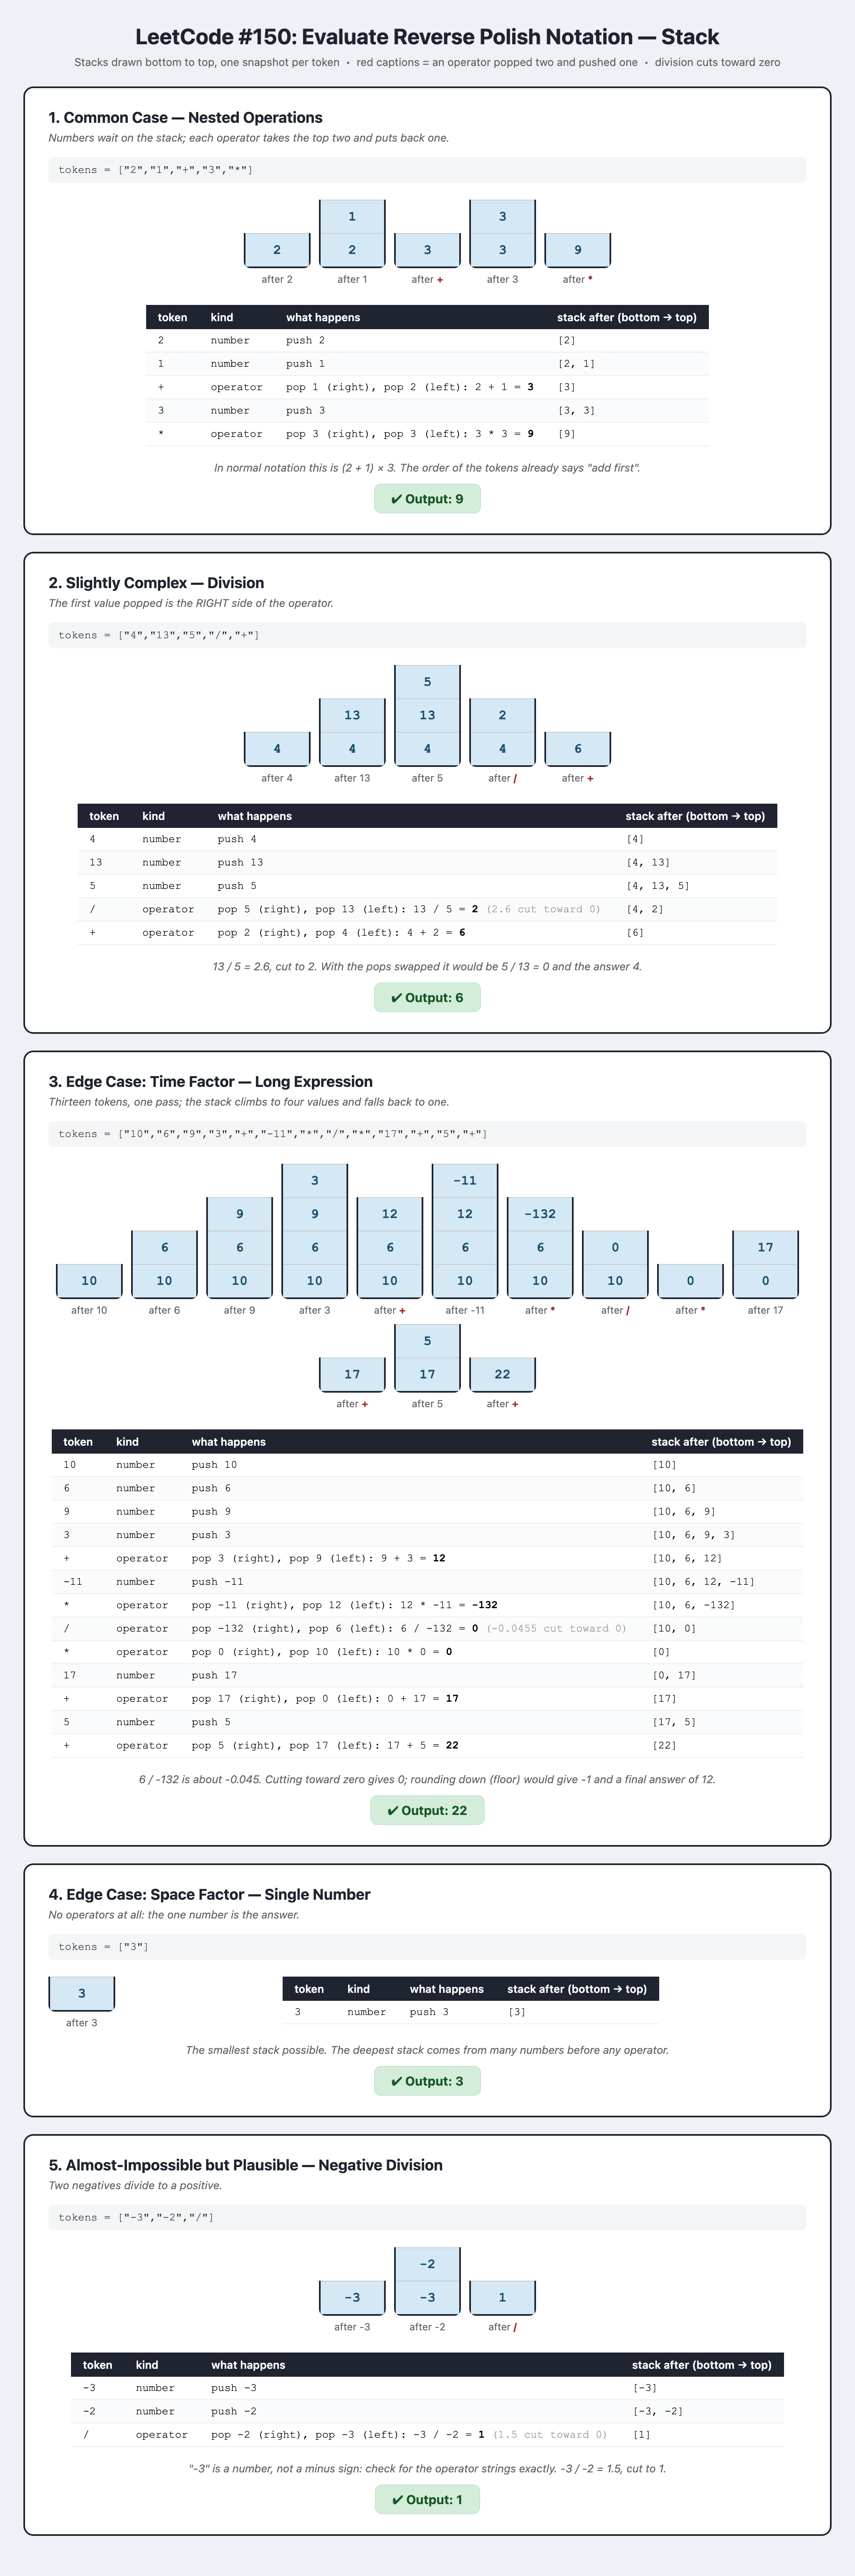